# 1. Preprocess intracranial EEG for the HMM

This is the first of three notebooks that walk through the full pipeline of the
paper:

| Notebook | What it does |
|---|---|
| `1_preprocess.ipynb` | download example recordings and preprocess them |
| `2_train.ipynb` | train a time-delay embedded HMM (TDE-HMM), choose the number of states, label the states and save the model |
| `3_apply.ipynb` | apply a model (the one you trained, or the released HUP model in `hup-model/`) to a recording and describe its states |

The model is a **single-channel** TDE-HMM: every channel is modelled as a
separate time series, so the same model applies to any number of channels from
any electrode layout (depth electrodes, strips or grids). The states are
zero-mean Gaussians that differ in their covariance of the time-delay embedded
signal, i.e. they differ in their **power spectrum**.

## Example data

Six 5-minute interictal stereo-EEG recordings from the HUP epilepsy cohort
([OpenNeuro ds004100](https://openneuro.org/datasets/ds004100)), about 120 MB in
total. Four subjects are used to train the model in the next notebook and two
are held out. To use your own data, point `preprocess` at your recordings
(see the end of this notebook).

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

STATE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

In [2]:
SFREQ = 100                 # sampling frequency after resampling (Hz)
LINE_FREQ = 60              # mains frequency of the recordings (50 Hz in Europe)
BAND_PASS = (0.1, 45)       # Hz

DATA_DIR = Path("data")
OUT_DIR = DATA_DIR / "preprocessed"
OUT_DIR.mkdir(parents=True, exist_ok=True)
URL = "https://s3.amazonaws.com/openneuro.org/ds004100"

TRAIN_SUBJECTS = ["sub-HUP060", "sub-HUP112", "sub-HUP133", "sub-HUP173"]
HELD_OUT_SUBJECTS = ["sub-HUP116", "sub-HUP117"]
SUBJECTS = TRAIN_SUBJECTS + HELD_OUT_SUBJECTS


def stem(subject):
    return f"{subject}_ses-presurgery_task-interictal_acq-seeg_run-01"


for subject in SUBJECTS:
    for suffix in ("_ieeg.edf", "_channels.tsv"):
        path = DATA_DIR / f"{stem(subject)}{suffix}"
        if not path.exists():
            print("downloading", path.name)
            urllib.request.urlretrieve(f"{URL}/{subject}/ses-presurgery/ieeg/{path.name}", path)
print("example data in", DATA_DIR.resolve())

example data in /Users/cgohil/projects/ucl/ieeg_hmm/repo/data


## Preprocessing steps

| Step | Setting | Why |
|---|---|---|
| Channels | good iEEG contacts only (the dataset's `channels.tsv`) | drop bad / non-EEG contacts |
| Reference | bipolar: adjacent contacts on the same shaft | removes the common reference and far-field signals; every channel then reflects local activity |
| Notch filter | line frequency and harmonics | mains interference |
| Band-pass filter | 0.1-45 Hz, FIR (zero-phase) | the frequency range the model describes |
| Resample | 100 Hz | the 11-sample embedding window (next notebook) then spans 110 ms |

No bad-segment removal is needed for these recordings. Each channel is z-scored
later, inside the model's data preparation, so the amplitude scale does not
matter here. Contact names are a shaft name followed by a number (`LA1`, `LA2`,
...); adapt `bipolar_pairs` to your own naming scheme if needed.

In [3]:
def bipolar_pairs(ch_names):
    """(anode, cathode) pairs of neighbouring contacts on the same shaft."""
    pairs = []
    for ch in ch_names:
        m = re.fullmatch(r"(.*?)(\d+)", ch)
        if m and f"{m[1]}{int(m[2]) + 1}" in ch_names:
            pairs.append((ch, f"{m[1]}{int(m[2]) + 1}"))
    return pairs


def preprocess(edf_path, channels_tsv):
    """Preprocess one recording -> MNE Raw with bipolar channels at SFREQ."""
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")
    channels = pd.read_csv(channels_tsv, sep="\t")
    raw.pick(channels.loc[channels["status"] == "good", "name"].tolist())

    pairs = bipolar_pairs(raw.ch_names)
    anodes, cathodes = [a for a, _ in pairs], [c for _, c in pairs]
    raw.set_channel_types({ch: "seeg" for ch in raw.ch_names})
    raw = mne.set_bipolar_reference(raw, anodes, cathodes, verbose="ERROR")
    raw.pick([f"{a}-{c}" for a, c in pairs])

    raw.notch_filter(np.arange(LINE_FREQ, raw.info["sfreq"] / 2, LINE_FREQ), verbose="ERROR")
    raw.filter(*BAND_PASS, fir_design="firwin", verbose="ERROR")
    raw.resample(SFREQ, verbose="ERROR")
    return raw


summary = []
for subject in SUBJECTS:
    raw = preprocess(DATA_DIR / f"{stem(subject)}_ieeg.edf", DATA_DIR / f"{stem(subject)}_channels.tsv")
    x = raw.get_data().astype(np.float32)                    # (n_channels, n_samples), volts
    np.savez(OUT_DIR / f"{subject}.npz", data=x, channels=np.array(raw.ch_names), sfreq=SFREQ)
    summary.append(dict(subject=subject, split="train" if subject in TRAIN_SUBJECTS else "held out",
                        bipolar_channels=len(raw.ch_names), duration_s=round(raw.times[-1])))
pd.DataFrame(summary)

,subject,split,bipolar_channels,duration_s
0,sub-HUP060,train,26,300
1,sub-HUP112,train,54,300
2,sub-HUP133,train,65,300
3,sub-HUP173,train,6,300
4,sub-HUP116,held out,37,300
5,sub-HUP117,held out,35,300


## A look at the data

Ten seconds of a few bipolar channels from one held-out subject. Interictal
epileptiform discharges (sharp transients) are visible on some channels; the
HMM will pick these out as one of its states.

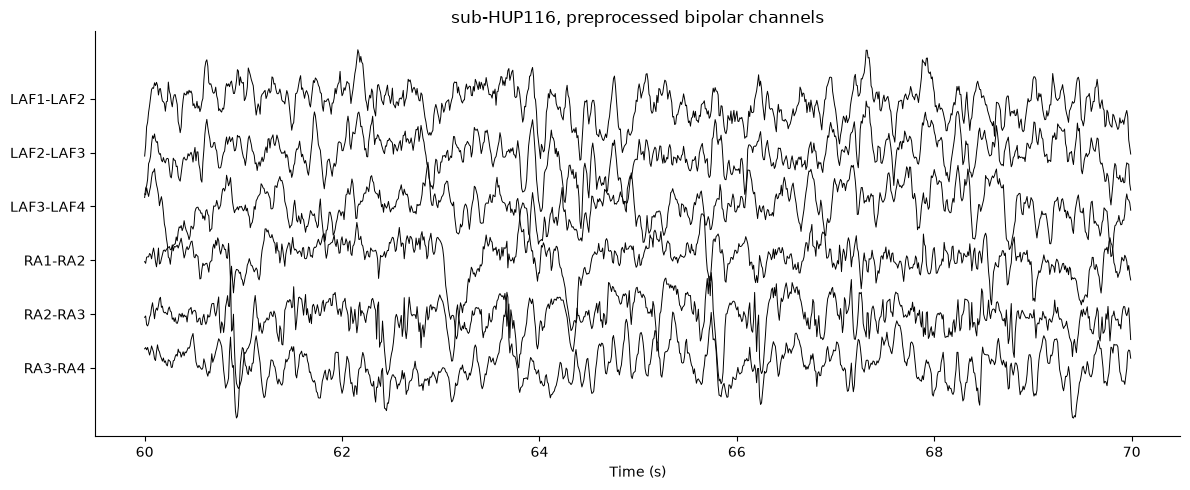

In [4]:
z = np.load(OUT_DIR / "sub-HUP116.npz")
x, names = z["data"], z["channels"]
t0, dur, n_show = 60, 10, 6                                   # s, s, channels
sl = slice(int(t0 * SFREQ), int((t0 + dur) * SFREQ))
t = np.arange(sl.start, sl.stop) / SFREQ

fig, ax = plt.subplots(figsize=(12, 5))
for i in range(n_show):
    y = x[i, sl] * 1e6                                        # microvolts
    ax.plot(t, y / (3 * y.std()) - i, color="black", lw=0.7)
ax.set_yticks(-np.arange(n_show), names[:n_show])
ax.set(xlabel="Time (s)", title="sub-HUP116, preprocessed bipolar channels")
fig.tight_layout()

## Using your own data

- Keep only good iEEG contacts and bipolar re-reference them. For ECoG grids,
  pair neighbouring contacts within a row; drop pairs that are far apart (for
  example more than 20 mm using the contact coordinates), which removes
  row-end pairs such as `G8-G9` on an 8 x 8 grid.
- Notch filter at your line frequency (50 or 60 Hz) and its harmonics,
  band-pass 0.1-45 Hz, resample to 100 Hz.
- Remove or annotate segments with large artefacts if your recordings have
  them; the model is robust to occasional artefacts but they will be assigned
  to a state.
- Save each recording as an `(n_channels, n_samples)` array as above; the next
  notebook reads everything in `data/preprocessed/`.